# Seven-day supplementary trajectory analysis

**Question:** How do forecast errors and trajectory diagnostics change when predicting a seven-day path?

This extends the forecast horizon to days 1–7. It does **not** change outbreak smoothing from 3 to 7 days, and does not change the outbreak definition.

- Same 585 ZIPs, 34 candidate inputs plus ZIP identity, 60-day calendar window with 14-day warmup, weekly parameter updates.
- Direct models for each horizon. Training target dates must be on or before the fit date; predicted targets follow the daily forecast date.
- Matched comparison: Apr 30–Dec 24 forecast dates so all seven targets end in 2020. Compare both three- and seven-day paths on these dates.
- Three days is the existing short-horizon benchmark; seven days tests a full-week path and longer endpoint separation. It is a sensitivity analysis, not a claim that seven days must be better.
- No 2021–2023 outcomes are used. Retrospective onset availability is assumed as in earlier notebooks.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if (ROOT/'Weikun').is_dir(): ROOT=ROOT/'Weikun'
assert (ROOT/'rolling_trajectory_outputs').exists(), 'Open this notebook from the Weikun folder.'
OUTPUT=ROOT/'mentor_followup_outputs'/'2026-11-04'
OUTPUT.mkdir(parents=True,exist_ok=True)
print('Output folder:',OUTPUT.resolve())


Output folder: C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\mentor_followup_outputs\2026-11-04


In [2]:
from pathlib import Path
import json,hashlib,time,os
import numpy as np,pandas as pd
GROUPS={
 'core_history':['cases_today','cases_lag_1','cases_lag_7','cases_lag_14'],
 'rolling_level':['cases_mean_7d','cases_mean_14d'],'volatility':['case_std_7d','case_std_14d'],
 'dynamics':['case_acceleration','case_jerk'],
 'local_rates':['case_rate_today_per_100k','case_rate_7d_per_100k','case_rate_14d_per_100k'],
 'sparse_history':['days_since_last_observed_case_censored','no_previous_observed_case'],
 'pressure':['nj_covid_pressure_7d','nj_covid_pressure_14d'],
 'month':[f'target_month_{k}' for k in range(2,13)],'weekday':[f'target_weekday_{k}' for k in range(2,8)]}
FEATURES=sum(GROUPS.values(),[])
FAMILIES={'local_case_history':sum([v for k,v in GROUPS.items() if k not in ['pressure','month','weekday']],[]),
 'commuting_pressure':GROUPS['pressure'],'calendar':GROUPS['month']+GROUPS['weekday']}
MODELS=['Dynamic Panel FE','XGBoost','Random Forest']

def run_seven(source,cohort,output):
 from scipy import sparse
 from sklearn.ensemble import RandomForestRegressor
 from xgboost import XGBRegressor
 output=Path(output);output.mkdir(parents=True,exist_ok=True)
 ids=pd.read_csv(cohort,dtype={'zip':str})['zip'].to_numpy(dtype='U5')
 dates=pd.date_range('2020-03-01','2020-12-31');origins=np.flatnonzero((dates>='2020-04-30')&(dates<='2020-12-24'))
 numeric=sum([v for k,v in GROUPS.items() if k not in ['month','weekday','sparse_history']],[])
 f=pd.read_csv(source,usecols=['zip','date','pressure_definition']+numeric,dtype={'zip':str},parse_dates=['date'])
 f=f.loc[f.zip.isin(ids)&f.date.isin(dates)]
 assert f.pressure_definition.eq('valid_population_nj_origins_renormalized_v2').all()
 assert not f.duplicated(['zip','date']).any() and len(ids)==585
 arrays={c:f.pivot(index='zip',columns='date',values=c).reindex(index=ids,columns=dates).to_numpy(float) for c in numeric}
 counts=arrays['cases_today'];actual=np.stack([counts[:,origins+h] for h in range(1,8)],axis=2)
 variants={'FULL':list(range(len(FEATURES)))}
 predictions={(m,g):np.full_like(actual,np.nan) for m in MODELS for g in variants}
 completed=set()
 for g in variants:
  for m in MODELS:
   path=output/f'predictions_{m.split()[0]}_7day.npz'
   if path.exists():
    with np.load(path,allow_pickle=False) as z:
     assert np.array_equal(z['actual_cases'],actual)
     predictions[m,g]=z['predictions'].copy();completed.add((m,g))
 for mm,gg in predictions:
  checkpoint=output/f'checkpoint_{mm.split()[0]}.npz'
  if checkpoint.exists() and (mm,gg) not in completed:
   with np.load(checkpoint) as z:predictions[mm,gg]=z['predictions'].copy()
 # Reuse identical previously fitted Days 1-3; only Days 4-7 require new fits.
 from threadpoolctl import threadpool_limits
 threadpool_limits(limits=1,user_api='blas')
 roots=Path(source).parents[2]
 baseline_files=['rolling_trajectory_outputs/rolling60_weekly_development_20261027/predictions.npz','xgboost_trajectory_outputs/xgb60_weekly_development_20261027/predictions.npz','random_forest_trajectory_outputs/rf60_weekly_development_20261027/predictions.npz']
 for mm,relative in zip(MODELS,baseline_files):
  with np.load(roots/relative) as zz:
   ix=pd.Index(zz['forecast_origins']).get_indexer(dates[origins]);assert (ix>=0).all()
   assert np.array_equal(zz['zip'],ids) and np.array_equal(zz['actual_cases'][:,ix,:],actual[:,:,:3])
   predictions[mm,'FULL'][:,:,:3]=np.maximum(zz['raw_predictions'][:,ix,:],0)
 first=dates.get_loc('2020-04-29');fits=np.unique(first+7*((origins-first)//7));logs=pd.read_csv(output/'training_audit.csv').to_dict('records') if (output/'training_audit.csv').exists() else []
 for fit in fits:
  lo=fit-59;batch=np.flatnonzero((origins>=fit)&(origins<fit+7));last=np.full(len(ids),-1)
  gap=np.full_like(counts,np.nan);never=np.full_like(counts,np.nan)
  for t in range(lo,int(origins[batch[-1]])+1):
   last=np.where(counts[:,t]>0,t,last);never[:,t]=last<0;gap[:,t]=np.where(last>=0,t-last,t-lo+1)
  arrays['days_since_last_observed_case_censored']=gap;arrays['no_previous_observed_case']=never
  for hh,h in enumerate(range(1,8)):
   train=np.arange(lo+14,fit-h+1);target=dates+pd.Timedelta(days=h)
   for k in range(2,13):arrays[f'target_month_{k}']=np.broadcast_to((target.month==k).astype(float),counts.shape)
   for k in range(2,8):arrays[f'target_weekday_{k}']=np.broadcast_to((target.dayofweek==k-1).astype(float),counts.shape)
   xt=np.stack([arrays[x][:,train] for x in FEATURES],axis=2);xp=np.stack([arrays[x][:,origins[batch]] for x in FEATURES],axis=2);yt=counts[:,train+h]
   assert np.isfinite(xt).all() and np.isfinite(xp).all()
   assert train[-1]+h<=fit and np.all(origins[batch]+h>fit) and lo>=0
   for g,cols in variants.items():
    xx,pp=xt[:,:,cols],xp[:,:,cols];features=[FEATURES[i] for i in cols]
    for m in MODELS:
     if (m,g) in completed or np.isfinite(predictions[m,g][:,batch,hh]).all():continue
     start=time.time()
     if m=='Dynamic Panel FE':
      xm=xx.mean(axis=1);ym=yt.mean(axis=1);xc=xx-xm[:,None];yc=yt-ym[:,None]
      norms=np.sqrt((xc*xc).mean(axis=(0,1)));scale=np.where(norms>1e-10,norms,1);z=(xc/scale).reshape(-1,len(cols));keep=[];q=[]
      for j in range(len(cols)):
       if norms[j]<1e-10:continue
       v=z[:,j].copy()
       for _ in range(2):
        for u in q:v-=u*(u@v)
       length=np.linalg.norm(v)
       if length<=1e-7*np.sqrt(len(v)):continue
       keep.append(j);q.append(v/length)
      b=np.linalg.lstsq(z[:,keep],yc.ravel(),rcond=None)[0]/scale[keep]
      yhat=np.einsum('ntp,p->nt',pp[:,:,keep],b)+(ym-xm[:,keep]@b)[:,None]
     elif m=='XGBoost':
      def design(v):
       d=pd.DataFrame(v.reshape(-1,len(cols)),columns=features);d['region_id']=pd.Categorical(np.repeat(ids,v.shape[1]),categories=ids);return d
      model=XGBRegressor(objective='reg:squarederror',tree_method='hist',n_estimators=200,max_depth=3,learning_rate=.05,min_child_weight=20,subsample=.8,colsample_bytree=1.,reg_lambda=5.,reg_alpha=0.,max_bin=128,enable_categorical=True,max_cat_to_onehot=4,max_cat_threshold=64,random_state=20261027,n_jobs=4)
      model.fit(design(xx),yt.ravel());yhat=model.predict(design(pp)).reshape(len(ids),len(batch))
     else:
      def design(v,fmt):
       rows=len(ids)*v.shape[1];identity=sparse.csr_matrix((np.ones(rows,dtype=np.float32),(np.arange(rows),np.repeat(np.arange(len(ids)),v.shape[1]))),shape=(rows,len(ids)))
       return sparse.hstack([sparse.csr_matrix(v.reshape(rows,len(cols)).astype(np.float32)),identity],format=fmt)
      model=RandomForestRegressor(n_estimators=200,max_depth=8,min_samples_leaf=20,max_features=1.,bootstrap=True,max_samples=.8,criterion='squared_error',random_state=20261027,n_jobs=4)
      model.fit(design(xx,'csc'),yt.ravel());yhat=model.predict(design(pp,'csr')).reshape(len(ids),len(batch))
     predictions[m,g][:,batch,hh]=np.maximum(yhat,0)
     logs.append(dict(model=m,drop_group=g,fit_date=str(dates[fit].date()),window_start=str(dates[lo].date()),latest_training_target=str(dates[train[-1]+h].date()),first_forecast_target=str(dates[origins[batch[0]]+h].date()),horizon=h,features=len(cols),seconds=time.time()-start))
  for (mm,gg),ppred in predictions.items():
   np.savez_compressed(output/f'checkpoint_{mm.split()[0]}.npz',predictions=ppred)
  pd.DataFrame(logs).to_csv(output/'training_audit.csv',index=False)
  print('Completed diagnostic refit',dates[fit].date(),flush=True)
 for (m,g),pred in predictions.items():
  assert np.isfinite(pred).all()
  if (m,g) not in completed:np.savez_compressed(output/f'predictions_{m.split()[0]}_7day.npz',predictions=pred,actual_cases=actual,zip=ids,daily_forecast_dates=dates[origins].to_numpy(),horizons=list(range(1,8)))
 if logs:pd.DataFrame(logs).to_csv(output/'training_audit.csv',index=False)
 (output/'protocol.json').write_text(json.dumps(dict(window=60,retrain_every=7,horizons=list(range(1,8)),features=FEATURES,scope='2020 exploratory validation only; retrospective onset availability assumed',daily_forecast_dates=['2020-04-30','2020-12-24'],label_boundary='latest training target <= fit date; target > forecast date'),indent=2))
 return predictions


from pathlib import Path
import json,itertools
import numpy as np,pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

NAMES=['Dynamic Panel FE','XGBoost','Random Forest']
PATHS=['rolling_trajectory_outputs/rolling60_weekly_development_20261027/predictions.npz','xgboost_trajectory_outputs/xgb60_weekly_development_20261027/predictions.npz','random_forest_trajectory_outputs/rf60_weekly_development_20261027/predictions.npz']
def load_models(root):
 data=[]
 for p in PATHS:
  with np.load(Path(root)/p,allow_pickle=False) as z:data.append({k:z[k].copy() for k in z.files})
 for d in data[1:]:
  for k in ['zip','forecast_origins','actual_cases','horizons']:assert np.array_equal(d[k],data[0][k]),k
 return data

def complementarity(root,output):
 from warning_helpers import warning_events
 root=Path(root);output=Path(output)/'model_complementarity';output.mkdir(parents=True,exist_ok=True)
 data=load_models(root);truth=data[0]['actual_cases'];dates=data[0]['forecast_origins'];ids=data[0]['zip']
 actual=np.sign(truth[:,:,2]-truth[:,:,0]);pred=np.stack([np.sign(np.maximum(d['raw_predictions'],0)[:,:,2]-np.maximum(d['raw_predictions'],0)[:,:,0]) for d in data])
 correct=pred==actual;rows=[];patterns=[]
 for cls,label in [(-1,'Declining'),(0,'Exact endpoint-flat'),(1,'Rising')]:
  mask=actual==cls;v=correct[:,mask];counts=v.sum(axis=0)
  rows.append(dict(actual_class=label,paths=int(mask.sum()),DP_recall=v[0].mean(),XGB_recall=v[1].mean(),RF_recall=v[2].mean(),at_least_one_correct=(counts>=1).mean(),at_least_two_correct=(counts>=2).mean(),all_three_correct=(counts==3).mean(),all_three_wrong=(counts==0).mean()))
  for bits in itertools.product([False,True],repeat=3):patterns.append(dict(actual_class=label,DP_correct=bits[0],XGB_correct=bits[1],RF_correct=bits[2],paths=int((v==np.array(bits)[:,None]).all(axis=0).sum())))
 pd.DataFrame(rows).to_csv(output/'direction_overlap_by_actual_class.csv',index=False);pd.DataFrame(patterns).to_csv(output/'direction_correctness_patterns.csv',index=False)
 # Union of correct outcomes is descriptive coverage, NOT a deployable selector.
 rules=[]
 for cls,label in [(-1,'Declining'),(1,'Rising')]:
  for votes in [1,2,3]:
   alert=(pred==cls).sum(axis=0)>=votes;positive=actual==cls
   rules.append(dict(direction=label,required_votes=votes,alerts=int(alert.sum()),recall=(alert&positive).sum()/positive.sum(),precision=(alert&positive).sum()/alert.sum() if alert.any() else np.nan))
 pd.DataFrame(rules).to_csv(output/'direction_vote_rules.csv',index=False)
 warning=root/'outbreak_task_outputs'/'case_surge_v1_20261101'
 if not warning.exists():
  matches=list(root.rglob('case_surge_v1_20261101/warning_metrics.csv'));assert matches,'Locate Notebook 27 warning outputs';warning=matches[0].parent
 risk=[]
 for m in NAMES:
  f=pd.read_csv(warning/(m.lower().replace(' ','_')+'_risk_scores.csv.gz'),dtype={'zip':str})
  f=f.sort_values(['zip','forecast_origin']).reset_index(drop=True);risk.append(f)
 for f in risk[1:]:
  for k in ['zip','forecast_origin','eligible','event_in_next_3_days']:assert f[k].equals(risk[0][k]),k
 wd=np.sort(risk[0].forecast_origin.unique()).astype('datetime64[D]');n=len(wd)
 scores=np.stack([f.risk_score.to_numpy().reshape(len(ids),n) for f in risk]);eligible=risk[0].eligible.to_numpy().reshape(len(ids),n)
 labels=pd.read_csv(warning/'daily_event_labels_2020.csv.gz',dtype={'zip':str},parse_dates=['date'])
 pivot=labels.pivot(index='zip',columns='date',values='onset').reindex(ids);calendar=pivot.columns.to_numpy().astype('datetime64[D]');onsets=pivot.to_numpy(bool)
 thresholds=pd.read_csv(warning/'warning_metrics.csv').query("phase=='calibration'").set_index('model').threshold.reindex(NAMES).to_numpy()
 votes=scores>thresholds[:,None,None];mask=wd>=np.datetime64('2020-09-01');metrics=[];evectors=[]
 for m,v in zip(NAMES,votes):
  met,alarms,ev=warning_events(v[:,mask].astype(float),eligible[:,mask],onsets,wd[mask],calendar,.5)
  metrics.append(dict(rule=m,**met));evectors.append(ev.set_index(['region_index','event_date']).detected)
  alarms.to_csv(output/(m.split()[0]+'_warning_episodes.csv'),index=False)
 event=pd.concat(evectors,axis=1,keys=NAMES);assert event.notna().all().all();event['models_detecting']=event[NAMES].sum(axis=1);event.reset_index().to_csv(output/'event_detection_overlap.csv',index=False)
 overlap=event.models_detecting.value_counts().reindex(range(4),fill_value=0).rename_axis('models_detecting').reset_index(name='events');overlap['share']=overlap.events/len(event);overlap.to_csv(output/'event_overlap_counts.csv',index=False)
 pairs=[]
 for left,right in itertools.combinations(NAMES,2):
  x,y=event[left],event[right];pairs.append(dict(model_A=left,model_B=right,both_detect=int((x&y).sum()),only_A=int((x&~y).sum()),only_B=int((~x&y).sum()),both_miss=int((~x&~y).sum()),jaccard=(x&y).sum()/(x|y).sum()))
 pd.DataFrame(pairs).to_csv(output/'event_pair_overlap.csv',index=False)
 for k in [1,2,3]:
  met,alarms,ev=warning_events((votes.sum(axis=0)>=k)[:,mask].astype(float),eligible[:,mask],onsets,wd[mask],calendar,.5)
  metrics.append(dict(rule=f'At least {k} model votes',**met));alarms.to_csv(output/f'vote{k}_warning_episodes.csv',index=False)
 pd.DataFrame(metrics).to_csv(output/'warning_vote_metrics.csv',index=False)
 fig,ax=plt.subplots(figsize=(10,4));r=pd.DataFrame(rows).set_index('actual_class');r[['DP_recall','XGB_recall','RF_recall','at_least_one_correct']].plot.bar(ax=ax);ax.set(ylabel='Fraction of actual paths',ylim=(0,1),title='Do models recognize different paths?');ax.tick_params(axis='x',rotation=0);fig.tight_layout();fig.savefig(output/'direction_overlap.png',dpi=200);plt.close(fig)
 fig,axs=plt.subplots(1,2,figsize=(12,4));r=pd.DataFrame(metrics)
 from matplotlib.ticker import PercentFormatter
 for ax,key,title in zip(axs,['event_recall','warning_precision'],['Detected events / eligible events','Correct warnings / issued warnings']):
  bars=ax.bar(np.arange(len(r)),r[key],color=['#64748b','#2563eb','#087f78']*2);ax.set(xticks=np.arange(len(r)),xticklabels=['DP','XGBoost','RF','1+ votes','2+ votes','3 votes'],ylim=(0,1),title=title);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.bar_label(bars,labels=[f'{100*x:.1f}%' for x in r[key]],padding=3)
 fig.tight_layout();fig.savefig(output/'warning_vote_comparison.png',dpi=200);plt.close(fig)
 text='# Three-model complementarity\n\n'+pd.DataFrame(rows).to_markdown(index=False)+'\n\n'+r.to_markdown(index=False)+'\n\nEvent overlap among original individual warning systems:\n\n'+overlap.to_markdown(index=False)+'\n\nUnion of correct paths is retrospective coverage, not attainable accuracy without knowing which model is correct. Voting rules are prospective functions of model outputs only. Votes are formed on the same ZIP-date BEFORE applying one shared cooldown and event matching, rather than unioning already-matched warnings. Individual thresholds are retained from original calibration; no new assessment tuning. This is exploratory 2020 analysis. Model votes are correlated; three votes do not constitute three independent pieces of evidence. The min/max model envelope is model disagreement, not a confidence or prediction interval.\n'
 (output/'RESULTS.md').write_text(text,encoding='utf-8');return r

def seven_summary(root,output):
 root=Path(root);folder=Path(output)/'seven_day_trajectory';data=load_models(root);rows=[];diag=[];saved={}
 for name,d in zip(NAMES,data):
  with np.load(folder/f'predictions_{name.split()[0]}_7day.npz') as z:p=z['predictions'];a=z['actual_cases'];dates=z['daily_forecast_dates']
  ix=pd.Index(d['forecast_origins']).get_indexer(dates);assert (ix>=0).all();assert np.array_equal(a[:,:,:3],d['actual_cases'][:,ix,:])
  old=np.maximum(d['raw_predictions'][:,ix,:],0);assert np.allclose(old,p[:,:,:3],rtol=1e-5,atol=1e-5),'Days 1-3 must reproduce existing models'
  saved[name]=p
  for h in range(7):rows.append(dict(model=name,horizon=h+1,MAE=np.abs(p[:,:,h]-a[:,:,h]).mean(),RMSE=np.sqrt(((p[:,:,h]-a[:,:,h])**2).mean()),bias=(p[:,:,h]-a[:,:,h]).mean(),forecast_dates=len(dates),regions=len(p)))
  for H in [3,7]:
   aa=a[:,:,:H];pp=p[:,:,:H];direction=np.sign(aa[:,:,-1]-aa[:,:,0]);pred=np.sign(pp[:,:,-1]-pp[:,:,0]);rec=[(pred[direction==c]==c).mean() for c in [-1,0,1]]
   diag.append(dict(model=name,path_days=H,path_MAE=np.abs(pp-aa).mean(),path_RMSE=np.sqrt(((pp-aa)**2).mean()),endpoint_direction_accuracy=(pred==direction).mean(),always_flat_reference=(direction==0).mean(),balanced_direction_accuracy=np.mean(rec),decline_recall=rec[0],flat_recall=rec[1],rise_recall=rec[2],strict_shape_accuracy=(np.sign(np.diff(pp,axis=2))==np.sign(np.diff(aa,axis=2))).all(axis=2).mean(),mean_daily_change_MAE=np.abs(np.diff(pp,axis=2)-np.diff(aa,axis=2)).mean(),endpoint_change_MAE=np.abs((pp[:,:,-1]-pp[:,:,0])-(aa[:,:,-1]-aa[:,:,0])).mean()))
 r=pd.DataFrame(rows);r.to_csv(folder/'horizon_metrics.csv',index=False);t=pd.DataFrame(diag);t.to_csv(folder/'matched_3_vs_7_day_paths.csv',index=False)
 fig,ax=plt.subplots(figsize=(9,4))
 for name,g in r.groupby('model',sort=False):ax.plot(g.horizon,g.MAE,'o-',label=name)
 ax.set(xlabel='Days ahead',ylabel='ZIP-level MAE (cases)',title='Same forecast dates: error by forecast horizon');ax.legend();fig.tight_layout();fig.savefig(folder/'horizon_MAE.png',dpi=200);plt.close(fig)
 fig,axs=plt.subplots(1,2,figsize=(11,4))
 for name,g in t.groupby('model',sort=False):
  axs[0].plot(g.path_days,g.endpoint_direction_accuracy,'o-',label=name);axs[1].plot(g.path_days,g.balanced_direction_accuracy,'o-',label=name)
 for ax,title in zip(axs,['Endpoint direction accuracy','Mean recall across 3 direction classes']):ax.set(title=title,xlabel='Path length (days)',xticks=[3,7],ylim=(0,1));ax.legend()
 fig.tight_layout();fig.savefig(folder/'direction_3_vs_7.png',dpi=200);plt.close(fig)
 fig,axs=plt.subplots(2,2,figsize=(11,7))
 for ax,day in zip(axs.ravel(),['2020-05-01','2020-07-01','2020-09-01','2020-11-01']):
  j=pd.Index(dates).get_loc(pd.Timestamp(day));ax.plot(range(1,8),a[:,j,:].sum(axis=0),'k-o',label='Actual')
  for name,p in saved.items():ax.plot(range(1,8),p[:,j,:].sum(axis=0),'o-',label=name)
  ax.set(title=f'Daily forecast date: {day}',xlabel='Days ahead',ylabel='Cases summed across 585 ZIPs',xticks=range(1,8));ax.legend(fontsize=8)
 fig.suptitle('Seven-day paths on four fixed calendar dates (aggregate illustration)');fig.tight_layout();fig.savefig(folder/'seven_day_path_examples.png',dpi=200);plt.close(fig)
 audits=[]
 for name,relative in zip(NAMES,PATHS):
  timing=pd.read_csv((root/relative).parent/'training_timing.csv');timing['model']=name;timing['prediction_source']='reused original Day 1-3 fits';audits.append(timing)
 audit=pd.concat(audits,ignore_index=True);audit.to_csv(folder/'reused_day1_3_training_audit.csv',index=False)
 new=pd.read_csv(folder/'training_audit.csv');assert (pd.to_datetime(new.latest_training_target)<=pd.to_datetime(new.fit_date)).all()
 assert (pd.to_datetime(audit.latest_training_target)<=pd.to_datetime(audit.fit_date)).all()
 (folder/'verification.json').write_text(json.dumps(dict(regions=int(len(a)),forecast_dates=len(dates),paths=int(len(a)*len(dates)),new_horizon_fits=int(len(new.query('horizon>=4'))),reused_horizon_fits=len(audit),first_three_horizons_match_original=True,all_training_labels_matured=True,targets_end_by='2020-12-31',horizon_definition='7 separate daily counts, not 7-day moving average'),indent=2))
 (folder/'RESULTS.md').write_text('# Seven-day supplementary trajectory analysis\n\n'+t.to_markdown(index=False)+'\n\n'+r.to_markdown(index=False)+'\n\nSame 585 ZIPs and Apr 30–Dec 24 daily forecast dates for both path lengths. 60 calendar days with 14-day warmup, weekly refits. All 34 candidates plus ZIP identity. Each horizon has its own direct model; only matured labels enter training. Days 1–3 reproduce prior predictions. Seven-day endpoint direction and six-step shape are different tasks from three-day direction and two-step shape: higher scores do not by themselves prove a better model. Read class recall and flat prevalence alongside accuracy. No outbreak labels, warning thresholds or lead-time results are changed here. 2020 exploratory historical replay; not untouched testing.\n',encoding='utf-8');return t


In [3]:
RUN_TRAINING=False  # Set True to fit all seven direct horizons; completed checkpoints resume.
FOLDER=OUTPUT/'seven_day_trajectory'
if RUN_TRAINING:
    run_seven(ROOT/'rolling_trajectory_outputs/inputs/nj_daily_features.csv.gz',ROOT/'fixed60_trajectory_outputs/fixed60_20261027/common_regions.csv',FOLDER)
else:
    print('Using saved seven-day predictions. Set RUN_TRAINING=True for a full rerun.')

Using saved seven-day predictions. Set RUN_TRAINING=True for a full rerun.


In [4]:
results=seven_summary(ROOT,OUTPUT)
display(results.round(4))
display(pd.read_csv(FOLDER/"horizon_metrics.csv").round(4))

,model,path_days,path_MAE,path_RMSE,endpoint_direction_accuracy,always_flat_reference,balanced_direction_accuracy,decline_recall,flat_recall,rise_recall,strict_shape_accuracy,mean_daily_change_MAE,endpoint_change_MAE
0,Dynamic Panel FE,3,0.7571,1.3835,0.2787,0.5728,0.3826,0.4708,0.0922,0.5849,0.1247,0.8735,0.8884
1,Dynamic Panel FE,7,0.8211,1.5290,0.2817,0.5633,0.3770,0.3498,0.0894,0.6917,0.0196,0.8855,1.0074
2,XGBoost,3,0.7369,1.3962,0.2244,0.5728,0.3477,0.4763,0.0036,0.5632,0.0884,0.8474,0.8578
3,XGBoost,7,0.7784,1.4989,0.2273,0.5633,0.3423,0.4485,0.0046,0.5738,0.0038,0.8614,0.9369
4,Random Forest,3,0.7344,1.3997,0.2183,0.5728,0.3400,0.4391,0.0000,0.5809,0.0823,0.8450,0.8577
5,Random Forest,7,0.7749,1.4953,0.2268,0.5633,0.3417,0.3833,0.0000,0.6417,0.0026,0.8598,0.9379


,model,horizon,MAE,RMSE,bias,forecast_dates,regions
0,Dynamic Panel FE,1,0.7295,1.3254,0.0655,239,585
1,Dynamic Panel FE,2,0.7549,1.3776,0.0809,239,585
2,Dynamic Panel FE,3,0.7870,1.4448,0.0964,239,585
3,Dynamic Panel FE,4,0.8189,1.5175,0.1078,239,585
4,Dynamic Panel FE,5,0.8522,1.5890,0.1304,239,585
5,Dynamic Panel FE,6,0.8845,1.6615,0.1479,239,585
6,Dynamic Panel FE,7,0.9211,1.7419,0.1685,239,585
7,XGBoost,1,0.7181,1.3515,0.0227,239,585
8,XGBoost,2,0.7353,1.3897,0.0178,239,585
9,XGBoost,3,0.7573,1.4459,0.0145,239,585


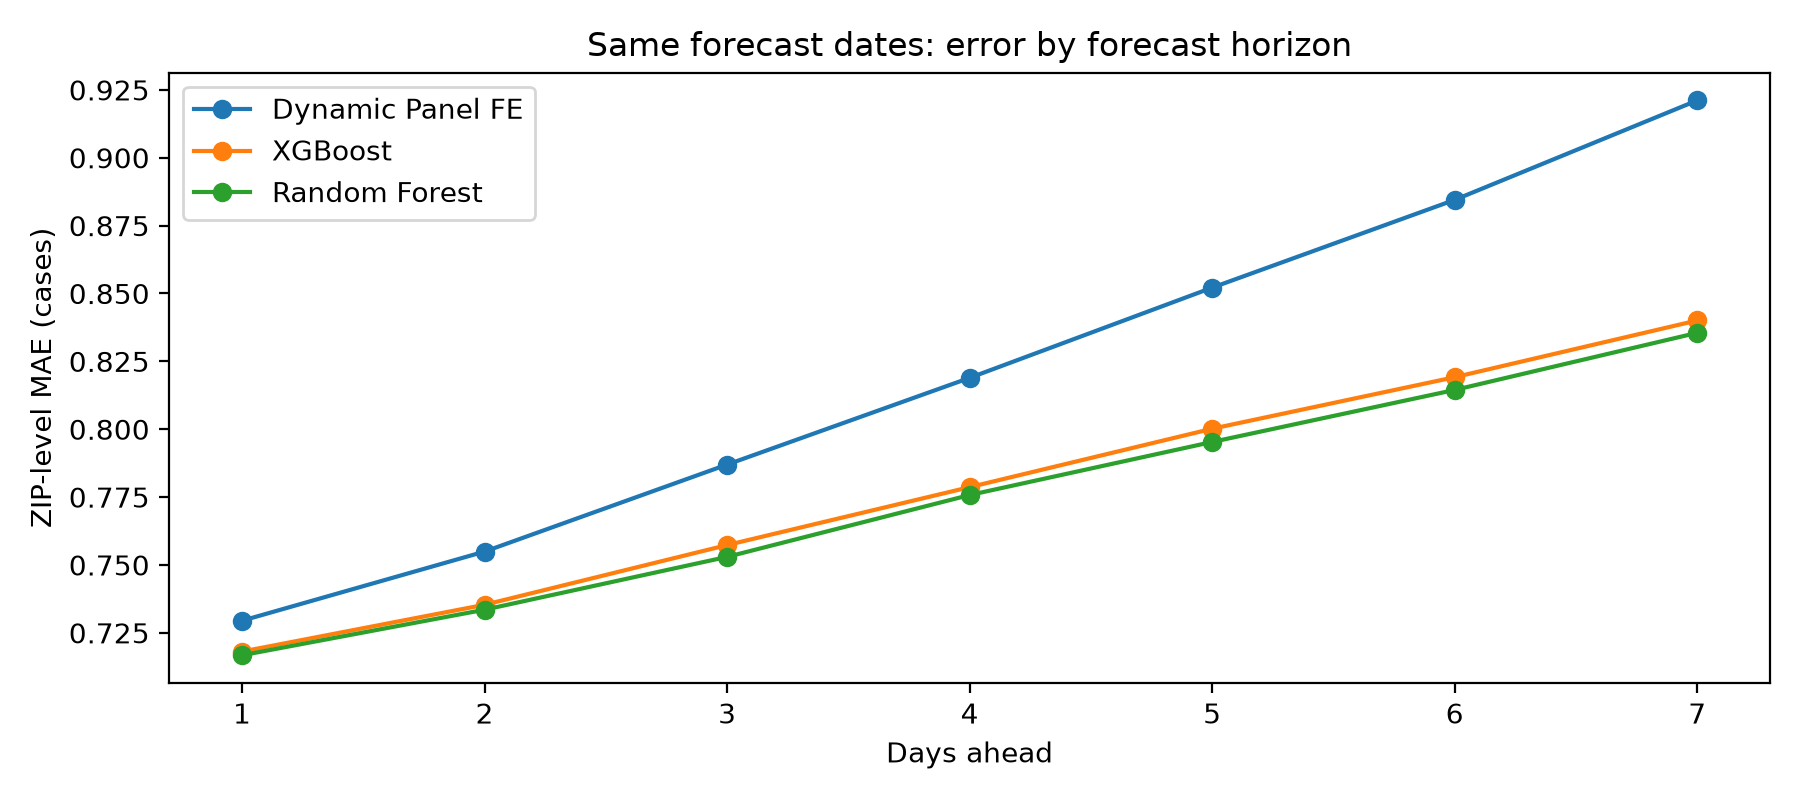

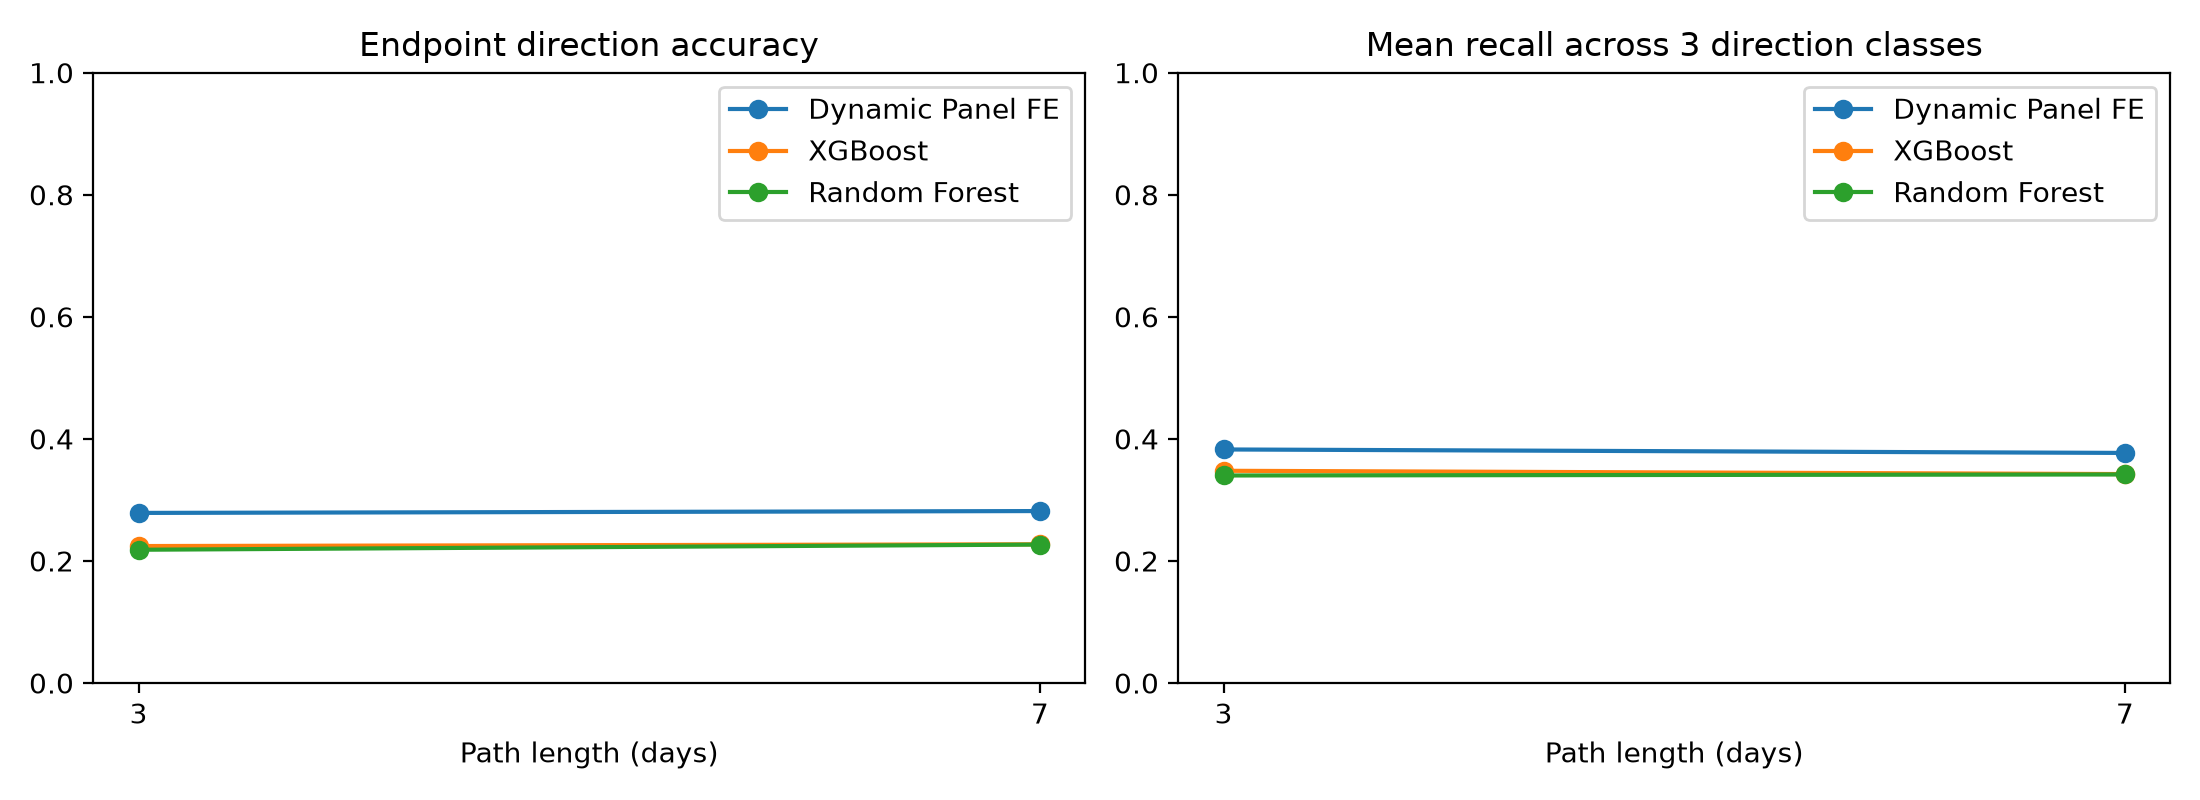

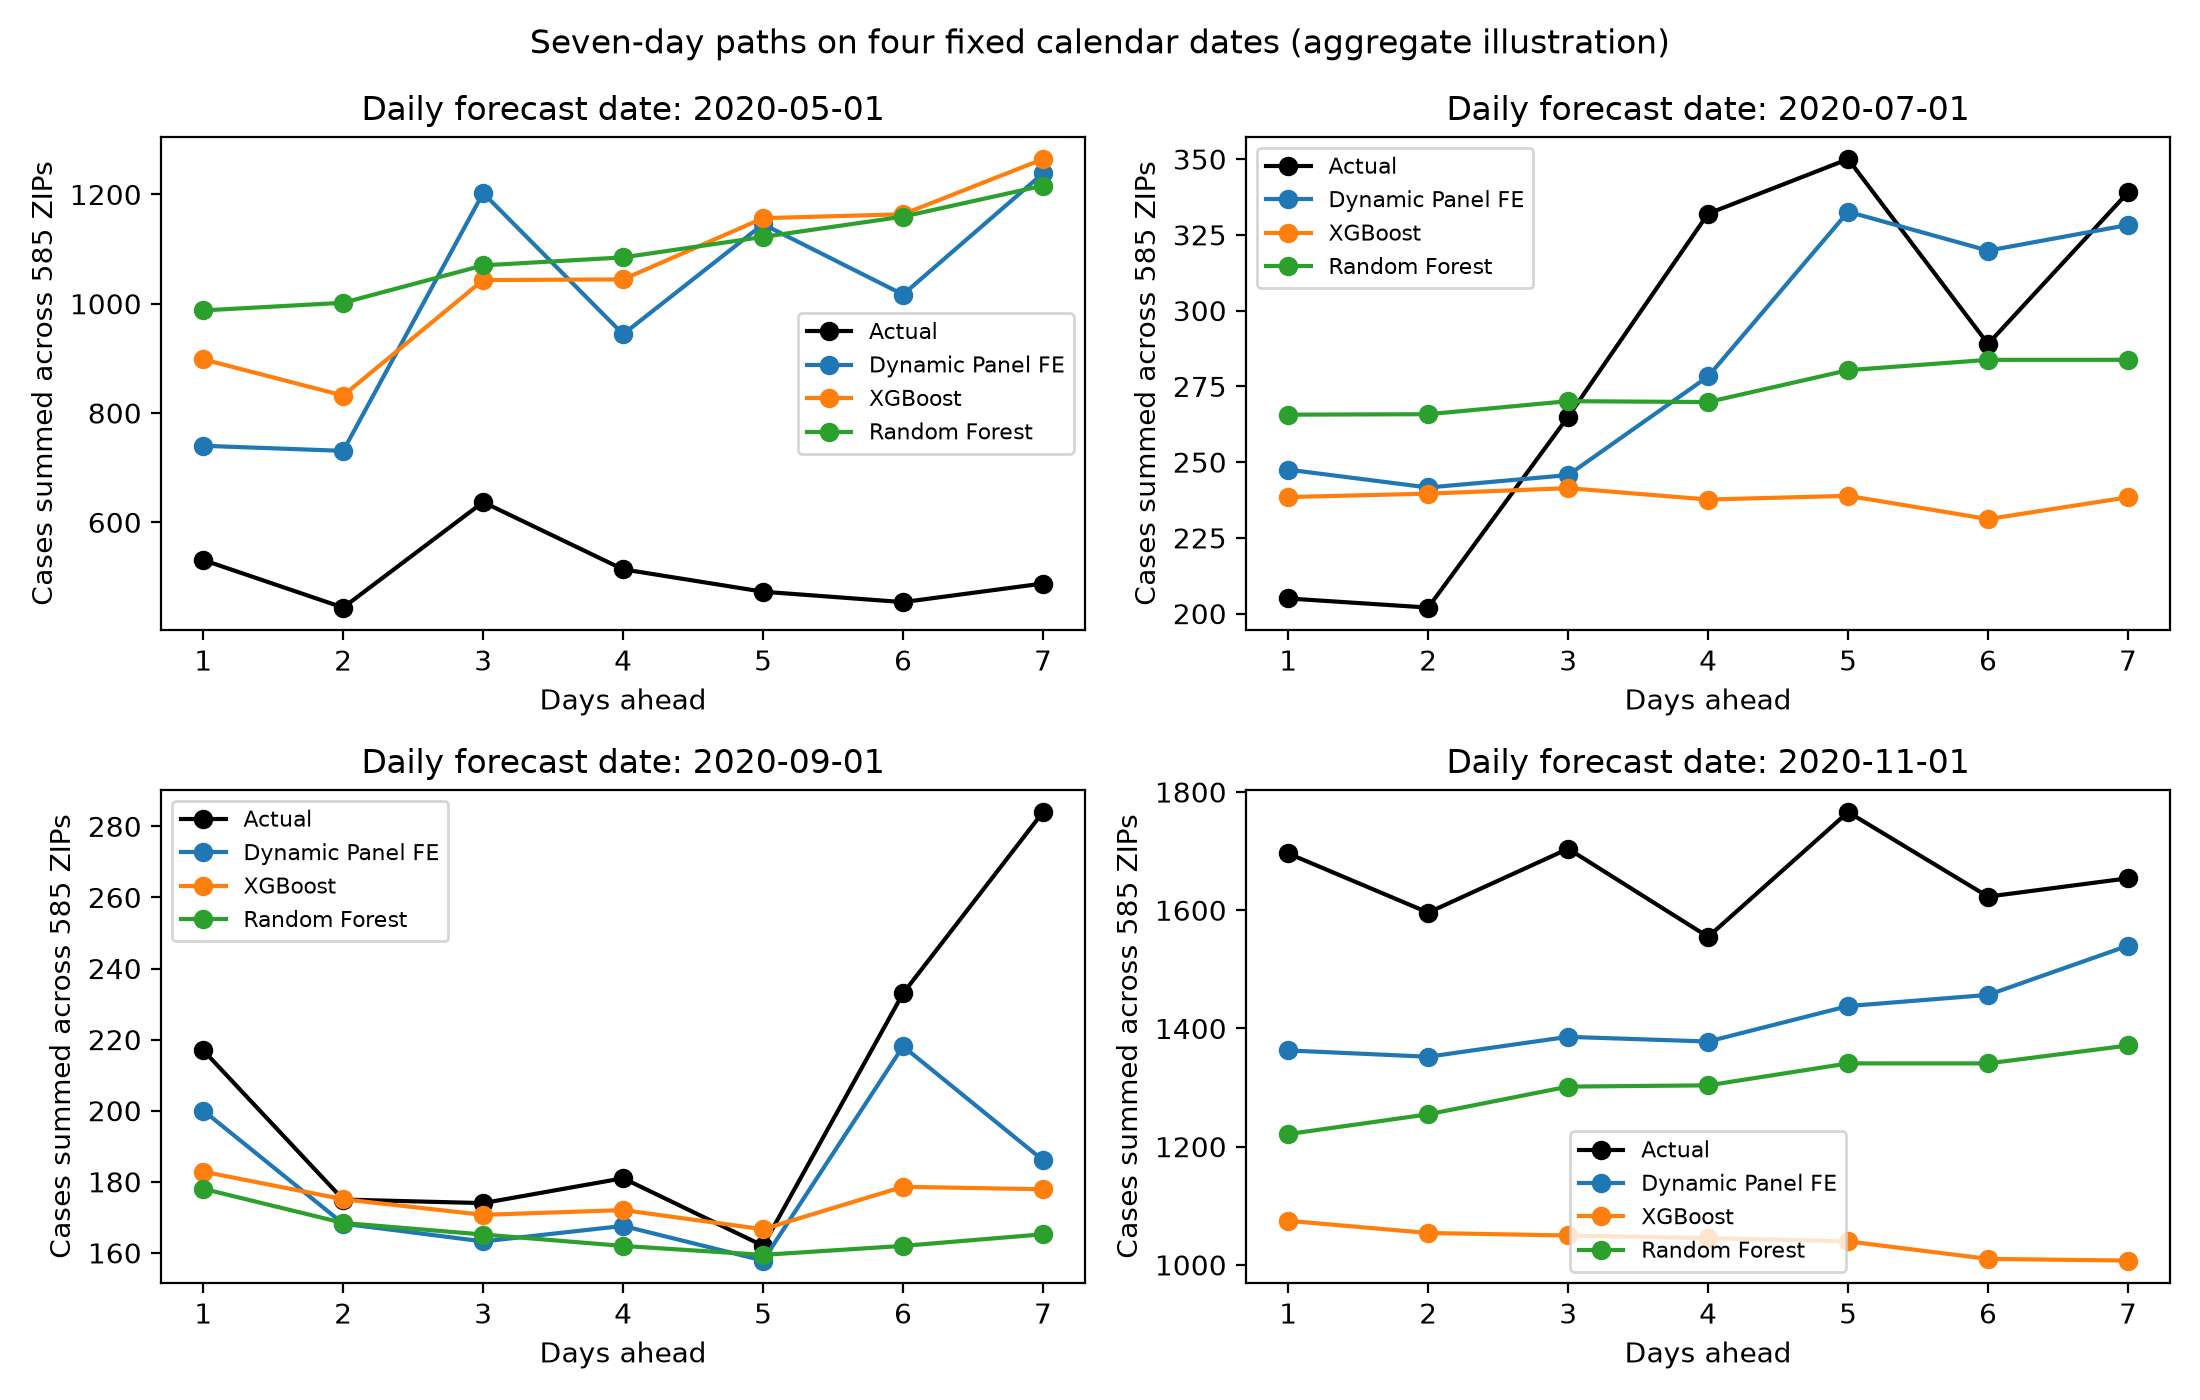

# Seven-day supplementary trajectory analysis

| model            |   path_days |   path_MAE |   path_RMSE |   endpoint_direction_accuracy |   always_flat_reference |   balanced_direction_accuracy |   decline_recall |   flat_recall |   rise_recall |   strict_shape_accuracy |   mean_daily_change_MAE |   endpoint_change_MAE |
|:-----------------|------------:|-----------:|------------:|------------------------------:|------------------------:|------------------------------:|-----------------:|--------------:|--------------:|------------------------:|------------------------:|----------------------:|
| Dynamic Panel FE |           3 |   0.757117 |     1.38346 |                      0.278661 |                0.572821 |                      0.382637 |         0.47081  |    0.0922099  |      0.58489  |              0.124686   |                0.873468 |              0.888373 |
| Dynamic Panel FE |           7 |   0.821149 |     1.52898 |                      0.281708 |                0.563316 |                      0.376961 |         0.349846 |    0.0893601  |      0.691676 |              0.0196474  |                0.885451 |              1.0074   |
| XGBoost          |           3 |   0.736912 |     1.39624 |                      0.224368 |                0.572821 |                      0.347703 |         0.476315 |    0.00362097 |      0.563172 |              0.0883739  |                0.847431 |              0.857756 |
| XGBoost          |           7 |   0.7784   |     1.49887 |                      0.227257 |                0.563316 |                      0.342313 |         0.448542 |    0.00458354 |      0.573815 |              0.00384794 |                0.861385 |              0.936917 |
| Random Forest    |           3 |   0.734404 |     1.39972 |                      0.218296 |                0.572821 |                      0.33999  |         0.439106 |    0          |      0.580863 |              0.0823445  |                0.845029 |              0.85774  |
| Random Forest    |           7 |   0.774893 |     1.49529 |                      0.226807 |                0.563316 |                      0.341684 |         0.383333 |    0          |      0.64172  |              0.00255337 |                0.859798 |              0.937887 |

| model            |   horizon |      MAE |    RMSE |        bias |   forecast_dates |   regions |
|:-----------------|----------:|---------:|--------:|------------:|-----------------:|----------:|
| Dynamic Panel FE |         1 | 0.729459 | 1.32539 |  0.0655281  |              239 |       585 |
| Dynamic Panel FE |         2 | 0.75492  | 1.3776  |  0.0809028  |              239 |       585 |
| Dynamic Panel FE |         3 | 0.786972 | 1.44479 |  0.0963735  |              239 |       585 |
| Dynamic Panel FE |         4 | 0.818916 | 1.51746 |  0.107765   |              239 |       585 |
| Dynamic Panel FE |         5 | 0.85215  | 1.58898 |  0.130378   |              239 |       585 |
| Dynamic Panel FE |         6 | 0.884492 | 1.66155 |  0.147908   |              239 |       585 |
| Dynamic Panel FE |         7 | 0.921131 | 1.74193 |  0.168549   |              239 |       585 |
| XGBoost          |         1 | 0.71809  | 1.35149 |  0.0226543  |              239 |       585 |
| XGBoost          |         2 | 0.735326 | 1.38974 |  0.0178318  |              239 |       585 |
| XGBoost          |         3 | 0.757319 | 1.44589 |  0.0145448  |              239 |       585 |
| XGBoost          |         4 | 0.778656 | 1.49896 |  0.00535938 |              239 |       585 |
| XGBoost          |         5 | 0.800182 | 1.54241 |  0.00673156 |              239 |       585 |
| XGBoost          |         6 | 0.819165 | 1.59436 | -0.00906748 |              239 |       585 |
| XGBoost          |         7 | 0.840066 | 1.64617 | -0.0157837  |              239 |       585 |
| Random Forest    |         1 | 0.716735 | 1.35818 |  0.0715244  |              239 |       585 |
| Random Forest    |         2 | 0.733507 | 1.39675 |  0.076339   |              239 |       585 |
| Random Forest    |         3 | 0.75297  | 1.44295 |  0.0837036  |              239 |       585 |
| Random Forest    |         4 | 0.775753 | 1.49962 |  0.0797143  |              239 |       585 |
| Random Forest    |         5 | 0.795306 | 1.54153 |  0.0831749  |              239 |       585 |
| Random Forest    |         6 | 0.81447  | 1.5831  |  0.0851545  |              239 |       585 |
| Random Forest    |         7 | 0.835507 | 1.62546 |  0.0922825  |              239 |       585 |

Same 585 ZIPs and Apr 30–Dec 24 daily forecast dates for both path lengths. 60 calendar days with 14-day warmup, weekly refits. All 34 candidates plus ZIP identity. Each horizon has its own direct model; only matured labels enter training. Days 1–3 reproduce prior predictions. Seven-day endpoint direction and six-step shape are different tasks from three-day direction and two-step shape: higher scores do not by themselves prove a better model. Read class recall and flat prevalence alongside accuracy. No outbreak labels, warning thresholds or lead-time results are changed here. 2020 exploratory historical replay; not untouched testing.


In [5]:
from IPython.display import display,Image,Markdown
display(Image(filename=str(FOLDER/'horizon_MAE.png')))
display(Image(filename=str(FOLDER/'direction_3_vs_7.png')))
display(Image(filename=str(FOLDER/'seven_day_path_examples.png')))
display(Markdown((FOLDER/'RESULTS.md').read_text(encoding='utf-8')))

## How to interpret the comparison
1. Day 1–3 predictions must reproduce the previous models on common dates. This is checked before reporting results.
2. Read daily MAE by horizon to assess whether distant forecasts become harder.
3. Endpoint direction compares Day 3 with Day 1, or Day 7 with Day 1. Class prevalence changes, so report flat reference and balanced accuracy as well as overall accuracy.
4. Seven-day strict shape requires SIX movement signs to match; three-day shape requires TWO. Scores are not directly equivalent in difficulty.
5. A seven-day path is not a seven-day average. Higher endpoint agreement can reflect longer separation and a different task.
6. No seven-day outbreak warning/AP/lead-time claim is made. Extending warnings would require separately defining and recalibrating a seven-day warning protocol.
7. Hyperparameters are retained from the existing models. This is horizon sensitivity under one fixed configuration, not a fully optimized model contest.